# 02 - Does Taste Match predict the rating a user later gives?

Runs on fake data only (`npm run fake:load`). Analysing real users needs a privacy policy and anonymisation first (spec 04).

This is spec 03 section 7.1 and 7.3: the **offline** evaluation and the weight tuning. The bar to
clear is *"beat the IMDb rating alone"*.

**Method.** For every rating a fake user posted, rebuild the score the app would have shown them
for that title from the history they had *strictly before* it (`cinecircle_analysis.replay`, which
uses the app's own `taste.score` functions), and compare it with the rating they then gave.

- **Title formula** (Discover): `100 * (0.7 G + 0.3 Q)`, defined whenever the user had any history.
- **Feed formula** (Home): `100 * (0.5 G + 0.3 S + 0.2 Q)`, defined only when someone the user
  followed had already shared a rating of that title (`S`).
- **Baseline:** the title's IMDb rating, through the same procedure.
- **Time split:** the first 60% of predictions in time calibrate a line `rating ~ a + b * score`
  (for MAE); the later 40% give Spearman's rho and MAE. Weights are chosen by the train rho only.

Two things to keep in mind throughout. The data is generated, so the numbers describe the
generator, not people (see the end). And the feed formula only exists on a subset of the rows, so
it must be compared with the others **on that same subset**.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cinecircle_analysis.frames import dataset_from_db
from cinecircle_analysis.load import assert_local
from cinecircle_analysis.replay import (
    evaluate, feed_score, fit_line, imdb_only, mae, predictions, spearman, title_score,
    tune_feed, tune_title,
)
from cinecircle_api.db import make_engine
from cinecircle_api.settings import Settings

engine = make_engine(Settings().database_url)
assert_local(engine)  # raises before any query unless the database is on this machine

BLUE, ORANGE, GREY = "#3b6fb6", "#d9822b", "#8a8a8a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.figsize": (7, 4)})

dataset = dataset_from_db(engine)  # exactly what is stored, not a fresh generate()
preds = predictions(dataset)
with_s = [p for p in preds if p.s is not None]  # rows where the feed formula exists

pd.DataFrame({
    "posts in the database": [len(dataset.posts)],
    "predictions (user had history)": [len(preds)],
    "...of which cold start": [sum(p.state == "cold" for p in preds)],
    "...of which with S (feed formula)": [len(with_s)],
}).T.rename(columns={0: "n"})

,n
posts in the database,3000
predictions (user had history),2987
...of which cold start,235
...of which with S (feed formula),1039


## 1. Head-to-head

**Table A, all predictions:** the title formula against IMDb only. Both are defined on every row,
so they are judged on identical rows.

**Table B, the subset with S:** `evaluate` drops rows whose score is `None` *before* the time
split, so running the feed formula on all predictions and IMDb on all predictions would compare
different rows with different splits. Instead all three scores are evaluated on the same
pre-filtered list `with_s`, so they share the rows and the split.

In [2]:
def as_table(evals):
    return pd.DataFrame(
        [{"score": e.name, "n_test": e.n_test, "rho": round(e.rho, 3), "MAE": round(e.mae, 3)}
         for e in evals]
    ).set_index("score")


table_a = as_table([
    evaluate(preds, title_score, "Taste Match (title formula)"),
    evaluate(preds, imdb_only, "IMDb only"),
])
table_b = as_table([
    evaluate(with_s, feed_score, "Taste Match (feed formula)"),
    evaluate(with_s, title_score, "Taste Match (title formula)"),
    evaluate(with_s, imdb_only, "IMDb only"),
])
print("A. all predictions (", len(preds), "rows )")
display(table_a)
print("B. only predictions where a followed account had rated the title (", len(with_s), "rows )")
display(table_b)

A. all predictions ( 2987 rows )


,n_test,rho,MAE
score,,,
Taste Match (title formula),1195,0.605,1.060
IMDb only,1195,0.552,1.058


B. only predictions where a followed account had rated the title ( 1039 rows )


,n_test,rho,MAE
score,,,
Taste Match (feed formula),416,0.531,0.971
Taste Match (title formula),416,0.554,0.942
IMDb only,416,0.412,1.063


### How sure are we? A bootstrap by user

The test part has only a few hundred to a thousand rows, and one user's ratings are not
independent of each other. To see how much of a gap is just sampling noise, resample the **test
users** with replacement (all of a user's test rows move together, and every score is recomputed on
the same resampled rows), recompute rho each time, and look at the middle 95% of the 2,000
results. The interval for a *difference* in rho is the useful one. **Reading rule used in all
the findings: an interval that includes 0 means the difference is not established on this
sample, whatever the point estimate says.**

In [3]:
def split(rows, score_fn, train_share=0.6):
    """The same time split `evaluate` makes: sort by time, drop None scores, cut at 60%."""
    scored = [(p, s) for p in sorted(rows, key=lambda p: p.at) if (s := score_fn(p)) is not None]
    cut = math.floor(len(scored) * train_share + 1e-9)
    return scored[:cut], scored[cut:]


def rank(values):
    return pd.Series(values).rank().to_numpy()


def rank_corr(x, y):
    return float(np.corrcoef(rank(x), rank(y))[0, 1])


def bootstrap(rows, score_fns, pairs=(), draws=2000, seed=0):
    """Test rho per score, and the rho difference for each (a, b) pair, with 95% intervals from
    resampling the test users (paired: every score sees the same resampled rows)."""
    names = list(score_fns)
    tests = [split(rows, fn)[1] for fn in score_fns.values()]
    assert len({tuple((p.user, p.title) for p, _ in t) for t in tests}) == 1  # same test rows
    users = np.array([p.user for p, _ in tests[0]])
    y = np.array([p.actual for p, _ in tests[0]])
    xs = [np.array([s for _, s in t]) for t in tests]
    by_user = {u: np.flatnonzero(users == u) for u in np.unique(users)}
    keys = list(by_user)
    rng = np.random.default_rng(seed)
    rhos = np.empty((draws, len(xs)))
    for d in range(draws):
        idx = np.concatenate([by_user[keys[k]] for k in rng.integers(0, len(keys), len(keys))])
        ry = rank(y[idx])
        for j, x in enumerate(xs):
            rhos[d, j] = np.corrcoef(rank(x[idx]), ry)[0, 1]
    point = [rank_corr(x, y) for x in xs]
    out = {}
    for j, name in enumerate(names):
        low, high = np.percentile(rhos[:, j], [2.5, 97.5])
        out[name] = {"rho": point[j], "95% low": low, "95% high": high}
    for a, b in pairs:
        ja, jb = names.index(a), names.index(b)
        low, high = np.percentile(rhos[:, ja] - rhos[:, jb], [2.5, 97.5])
        out[f"{a} minus {b}"] = {"rho": point[ja] - point[jb], "95% low": low, "95% high": high}
    table = pd.DataFrame(out).T.round(3)
    table["interval includes 0"] = [
        "" if " minus " not in name else ("yes" if row["95% low"] <= 0 <= row["95% high"] else "no")
        for name, row in table.iterrows()
    ]
    return table


# the split above must agree with `evaluate` (guards against the two drifting apart)
for rows, fn in [(preds, title_score), (preds, imdb_only), (with_s, feed_score)]:
    test = split(rows, fn)[1]
    assert abs(spearman([s for _, s in test], [p.actual for p, _ in test])
               - evaluate(rows, fn, "check").rho) < 1e-12

print("A. all predictions, test users resampled")
display(bootstrap(preds, {"title formula": title_score, "IMDb only": imdb_only},
                  pairs=[("title formula", "IMDb only")]))
print("B. predictions with S (all three scores on the same rows)")
display(bootstrap(
    with_s,
    {"feed formula": feed_score, "title formula": title_score, "IMDb only": imdb_only},
    pairs=[("feed formula", "IMDb only"), ("title formula", "IMDb only"),
           ("feed formula", "title formula")],
))

A. all predictions, test users resampled


,rho,95% low,95% high,interval includes 0
title formula,0.605,0.538,0.669,
IMDb only,0.552,0.484,0.615,
title formula minus IMDb only,0.053,-0.003,0.112,yes


B. predictions with S (all three scores on the same rows)


,rho,95% low,95% high,interval includes 0
feed formula,0.531,0.437,0.607,
title formula,0.554,0.446,0.646,
IMDb only,0.412,0.317,0.509,
feed formula minus IMDb only,0.119,-0.003,0.219,yes
title formula minus IMDb only,0.142,0.013,0.255,no
feed formula minus title formula,-0.023,-0.058,0.012,yes


## 2. Where does the signal come from?

Each component on its own, judged the same way. `G` is the genre affinity from the user's own
ratings, `Q` the catalogue quality, `S` the followed-account signal. `Q` is the IMDb rating divided by
ten (TMDB only if IMDb is missing), so `Q` alone is the "IMDb only" row and gets no row of its own.

In [4]:
G = lambda p: 100 * p.g  # noqa: E731
S = lambda p: None if p.s is None else 100 * p.s  # noqa: E731

components = pd.concat([
    as_table([evaluate(preds, G, "G genre affinity"),
              evaluate(preds, imdb_only, "IMDb only")]).assign(rows="all predictions"),
    as_table([evaluate(with_s, G, "G genre affinity"),
              evaluate(with_s, S, "S followed-account signal"),
              evaluate(with_s, imdb_only, "IMDb only")]).assign(rows="only with S"),
])
display(components.reset_index().set_index(["rows", "score"]))

n_test    rho    MAE
rows            score                                          
all predictions G genre affinity             1195  0.400  1.229
                IMDb only                    1195  0.552  1.058
only with S     G genre affinity              416  0.391  1.083
                S followed-account signal     416  0.203  1.191
                IMDb only                     416  0.412  1.063

## 3. What does a score look like against the rating?

Left: on the held-out test part, the rating each score predicts (its calibrated line, fitted on
the train part) against the rating actually given. A perfect score would hug the diagonal; the
vertical spread is the noise the generator puts into every rating. Right: the same thing as a
decile chart, which is easier to read: sort the test rows by score, cut into ten equal groups and
plot the mean actual rating in each. A better score gives a steeper climb.

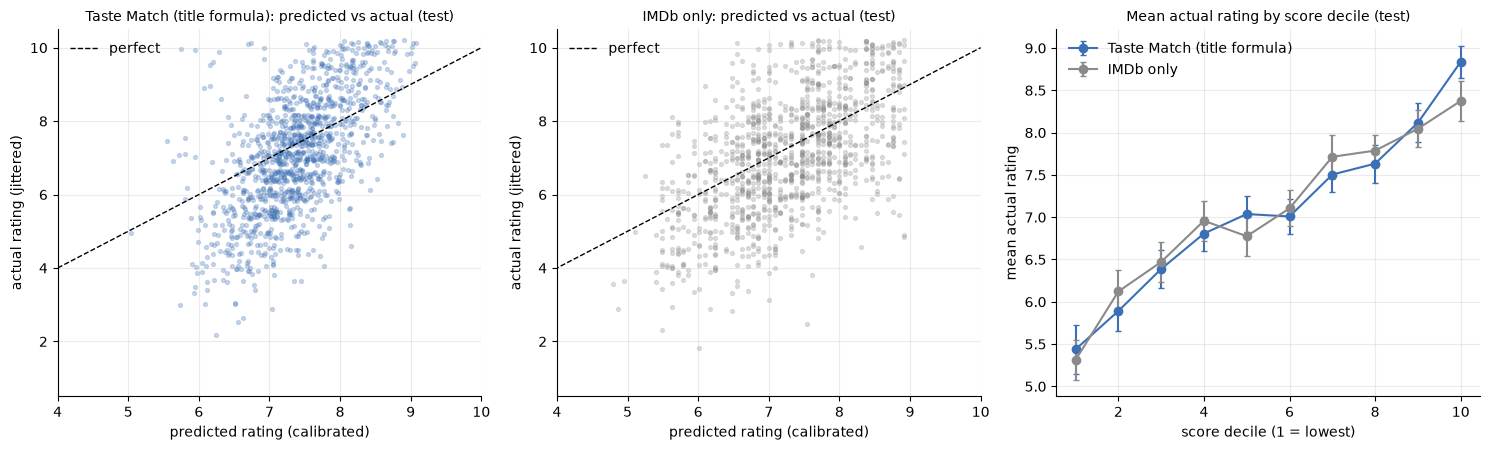

,Taste Match mean,"+/- (95%, rows)",IMDb mean,IMDb +/-
score decile,,,,
1,5.44,0.29,5.31,0.23
2,5.89,0.23,6.12,0.25
3,6.39,0.22,6.47,0.23
4,6.81,0.20,6.96,0.23
5,7.04,0.21,6.78,0.24
6,7.01,0.21,7.11,0.21
7,7.50,0.21,7.71,0.26
8,7.63,0.22,7.79,0.19
9,8.12,0.23,8.05,0.22


top decile: Taste Match 8.84 vs IMDb 8.38 (difference +0.46); bottom decile: 5.44 vs 5.31. Intervals treat rows as independent, so they are optimistic.


In [5]:
def calibrated(score_fn):
    train, test = split(preds, score_fn)
    a, b = fit_line([s for _, s in train], [p.actual for p, _ in train])
    x = np.array([s for _, s in test])
    return a + b * x, np.array([p.actual for p, _ in test]), x


fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
rng = np.random.default_rng(1)
for ax, (fn, label, color) in zip(
    axes[:2], [(title_score, "Taste Match (title formula)", BLUE), (imdb_only, "IMDb only", GREY)]
):
    predicted, actual, _ = calibrated(fn)
    ax.scatter(predicted, actual + rng.uniform(-0.2, 0.2, len(actual)), s=8, alpha=0.25,
               color=color)
    ax.plot([1, 10], [1, 10], color="black", linewidth=1, linestyle="--", label="perfect")
    ax.set(title=f"{label}: predicted vs actual (test)", xlabel="predicted rating (calibrated)",
           ylabel="actual rating (jittered)", xlim=(4, 10), ylim=(0.5, 10.5))
    ax.title.set_fontsize(10)
    ax.legend(frameon=False, loc="upper left")

ax = axes[2]
decile_means = {}
for fn, label, color in [(title_score, "Taste Match (title formula)", BLUE),
                         (imdb_only, "IMDb only", GREY)]:
    _, actual, x = calibrated(fn)
    decile = pd.qcut(pd.Series(x).rank(method="first"), 10, labels=False)
    means = pd.Series(actual).groupby(decile).agg(["mean", "sem"])
    decile_means[label] = means
    ax.errorbar(means.index + 1, means["mean"], yerr=1.96 * means["sem"], marker="o",
                color=color, label=label, capsize=2)
ax.set(title="Mean actual rating by score decile (test)", xlabel="score decile (1 = lowest)",
       ylabel="mean actual rating")
ax.title.set_fontsize(10)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

taste, base = decile_means["Taste Match (title formula)"], decile_means["IMDb only"]
deciles = pd.DataFrame({
    "Taste Match mean": taste["mean"].round(2), "+/- (95%, rows)": (1.96 * taste["sem"]).round(2),
    "IMDb mean": base["mean"].round(2), "IMDb +/-": (1.96 * base["sem"]).round(2),
})
deciles.index = deciles.index + 1
deciles.index.name = "score decile"
display(deciles)
print(f"top decile: Taste Match {taste['mean'].iloc[-1]:.2f} vs IMDb {base['mean'].iloc[-1]:.2f} "
      f"(difference {taste['mean'].iloc[-1] - base['mean'].iloc[-1]:+.2f}); bottom decile: "
      f"{taste['mean'].iloc[0]:.2f} vs {base['mean'].iloc[0]:.2f}. Intervals treat rows as "
      f"independent, so they are optimistic.")

**On MAE.** The calibration is a straight line fitted by least squares, and the posted rating
carries `N(0, 1)` noise on a half-step grid, so even a perfect predictor of the latent opinion
would miss by about 0.8 on average. That floor dominates MAE: a score can rank the ratings
noticeably better (higher rho) and still only shave a few hundredths off MAE. Rho is the metric
that separates the scores here; MAE is shown for completeness, next to a do-nothing baseline.

In [6]:
train, test = split(preds, title_score)
constant = np.mean([p.actual for p, _ in train])
print(f"always predict the train mean ({constant:.2f}): MAE {mae([constant] * len(test), [p.actual for p, _ in test]):.3f}")
display(table_a[["MAE"]])

always predict the train mean (7.49): MAE 1.297


,MAE
score,
Taste Match (title formula),1.060
IMDb only,1.058


## 4. Cold start versus a full profile

The app switches from the cold-start blend to the full formula after five ratings. The test rows
split by that state (the split itself is the global one above):

In [7]:
_, test_all = split(preds, title_score)
rows = []
for state in ("cold", "full"):
    part = [(p, s) for p, s in test_all if p.state == state]
    y = [p.actual for p, _ in part]
    rows.append({"state at prediction": state, "n_test": len(part),
                 "rho Taste Match (title)": round(spearman([s for _, s in part], y), 3),
                 "rho IMDb only": round(spearman([p.imdb for p, _ in part], y), 3)})
display(pd.DataFrame(rows).set_index("state at prediction"))

,n_test,rho Taste Match (title),rho IMDb only
state at prediction,,,
cold,30,0.341,0.513
full,1165,0.639,0.549


## 5. Tuning the weights

Spec 03 section 7.3: compare weight sets. The grids are the plan's: title weights `wG` from 0.3 to
0.9 (`wQ = 1 - wG`), and feed weights on the 0.1 simplex. Rows are **ordered by train rho** (the
only thing a real tuner would be allowed to look at); the test columns are what each choice would
then have scored on later data.

,wG,wQ,test rho,test MAE
train rank,,,,
1,0.4,0.6,0.644,0.953
2,0.3,0.7,0.626,0.971
3,0.5,0.5,0.651,0.958
4,0.6,0.4,0.639,0.995
5,0.7,0.3,0.605,1.060
6,0.8,0.2,0.548,1.129
7,0.9,0.1,0.477,1.187


best wG on train: 0.4  |  best wG on test: 0.5  |  spec default 0.7: rho 0.605  |  IMDb only: rho 0.552


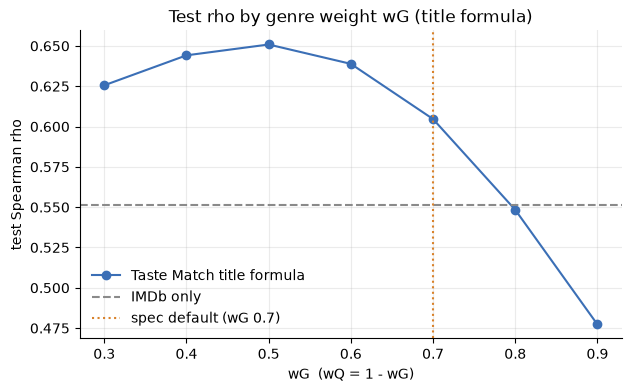

In [8]:
title_grid = tune_title(preds)
title_tuning = pd.DataFrame(
    [{"train rank": i + 1, "wG": wg, "wQ": round(1 - wg, 1), "test rho": round(ev.rho, 3),
      "test MAE": round(ev.mae, 3)} for i, (wg, ev) in enumerate(title_grid)]
).set_index("train rank")
display(title_tuning)

best_train_wg = title_grid[0][0]
best_test_wg = max(title_grid, key=lambda row: row[1].rho)[0]
spec_rho = next(ev.rho for wg, ev in title_grid if wg == 0.7)
imdb_rho = evaluate(preds, imdb_only, "IMDb only").rho
print(f"best wG on train: {best_train_wg}  |  best wG on test: {best_test_wg}  |  "
      f"spec default 0.7: rho {spec_rho:.3f}  |  IMDb only: rho {imdb_rho:.3f}")

by_wg = sorted(title_grid)
fig, ax = plt.subplots()
ax.plot([wg for wg, _ in by_wg], [ev.rho for _, ev in by_wg], marker="o", color=BLUE,
        label="Taste Match title formula")
ax.axhline(imdb_rho, color=GREY, linestyle="--", label="IMDb only")
ax.axvline(0.7, color=ORANGE, linestyle=":", label="spec default (wG 0.7)")
ax.set(title="Test rho by genre weight wG (title formula)", xlabel="wG  (wQ = 1 - wG)",
       ylabel="test Spearman rho")
ax.legend(frameon=False)
plt.show()

Are those differences real? A paired by-user bootstrap on the same test rows, every `wG` against
the spec's 0.7:

In [9]:
WGS = [wg for wg, _ in title_grid]  # train-rank order
title_fns = {f"wG={wg:.1f}": (lambda p, wg=wg: title_score(p, wg, round(1 - wg, 1))) for wg in WGS}
vs_spec = bootstrap(
    preds, title_fns, pairs=[(f"wG={wg:.1f}", "wG=0.7") for wg in WGS if wg != 0.7]
)
for wg, ev in title_grid:  # the bootstrap's point estimates are the tuning table's test rho
    assert abs(vs_spec.loc[f"wG={wg:.1f}", "rho"] - ev.rho) < 5e-4  # the table is rounded to 3 places
print(f"train-best wG = {best_train_wg}; every weight set minus the spec's 0.7:")
display(vs_spec[vs_spec.index.str.contains(" minus ")])

train-best wG = 0.4; every weight set minus the spec's 0.7:


,rho,95% low,95% high,interval includes 0
wG=0.4 minus wG=0.7,0.040,0.011,0.071,no
wG=0.3 minus wG=0.7,0.021,-0.017,0.061,yes
wG=0.5 minus wG=0.7,0.046,0.026,0.068,no
wG=0.6 minus wG=0.7,0.034,0.024,0.047,no
wG=0.8 minus wG=0.7,-0.056,-0.075,-0.043,no
wG=0.9 minus wG=0.7,-0.127,-0.169,-0.098,no


top 5 by train rho, with the spec default (0.5, 0.3, 0.2) for reference:


,wG,wS,wQ,test rho,test MAE
train rank,,,,,
1,0.5,0.1,0.4,0.576,0.924
2,0.4,0.1,0.5,0.554,0.944
3,0.5,0.0,0.5,0.570,0.924
4,0.4,0.2,0.4,0.553,0.951
5,0.5,0.2,0.3,0.566,0.938
16,0.5,0.3,0.2,0.531,0.971


best by test rho (not a legitimate choice, shown for the gap): wG=0.6, wS=0.0, wQ=0.4, rho 0.578
test rho of the grid with wS = 0 (no followed-account signal): {'min': 0.391, 'max': 0.578}


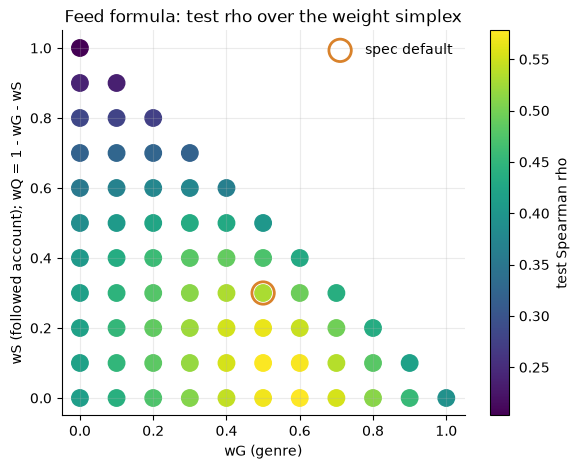

In [10]:
feed_grid = tune_feed(with_s)  # all rows here have S
feed_tuning = pd.DataFrame(
    [{"train rank": i + 1, "wG": w[0], "wS": w[1], "wQ": w[2], "test rho": round(ev.rho, 3),
      "test MAE": round(ev.mae, 3)} for i, (w, ev) in enumerate(feed_grid)]
).set_index("train rank")
spec_row = feed_tuning[(feed_tuning.wG == 0.5) & (feed_tuning.wS == 0.3)]
print("top 5 by train rho, with the spec default (0.5, 0.3, 0.2) for reference:")
display(pd.concat([feed_tuning.head(5), spec_row[~spec_row.index.isin(feed_tuning.head(5).index)]]))

best_by_test = feed_tuning.sort_values("test rho", ascending=False).iloc[0]
print(f"best by test rho (not a legitimate choice, shown for the gap): wG={best_by_test.wG}, "
      f"wS={best_by_test.wS}, wQ={best_by_test.wQ}, rho {best_by_test['test rho']}")
print("test rho of the grid with wS = 0 (no followed-account signal):",
      feed_tuning[feed_tuning.wS == 0]["test rho"].describe()[["min", "max"]].round(3).to_dict())

fig, ax = plt.subplots(figsize=(6.5, 5))
points = ax.scatter(feed_tuning.wG, feed_tuning.wS, c=feed_tuning["test rho"], s=140,
                    cmap="viridis")
ax.scatter([0.5], [0.3], s=260, facecolors="none", edgecolors=ORANGE, linewidths=2,
           label="spec default")
ax.set(title="Feed formula: test rho over the weight simplex", xlabel="wG (genre)",
       ylabel="wS (followed account); wQ = 1 - wG - wS")
ax.legend(frameon=False)
fig.colorbar(points, label="test Spearman rho")
plt.show()

In [11]:
best_feed = feed_grid[0][0]  # best by train rho
feed_fns = {
    f"train-best {best_feed}": lambda p: feed_score(p, *best_feed),
    "spec (0.5, 0.3, 0.2)": lambda p: feed_score(p, 0.5, 0.3, 0.2),
    "no S (0.5, 0.0, 0.5)": lambda p: feed_score(p, 0.5, 0.0, 0.5),
}
names = list(feed_fns)
vs_feed = bootstrap(with_s, feed_fns, pairs=[(names[0], names[1]), (names[2], names[1])])
print("feed weights on the S subset, paired by-user bootstrap:")
display(vs_feed)

feed weights on the S subset, paired by-user bootstrap:


,rho,95% low,95% high,interval includes 0
"train-best (0.5, 0.1, 0.4)",0.576,0.480,0.657,
"spec (0.5, 0.3, 0.2)",0.531,0.437,0.607,
"no S (0.5, 0.0, 0.5)",0.570,0.469,0.653,
"train-best (0.5, 0.1, 0.4) minus spec (0.5, 0.3, 0.2)",0.045,0.011,0.083,no
"no S (0.5, 0.0, 0.5) minus spec (0.5, 0.3, 0.2)",0.039,-0.005,0.091,yes


## 6. Findings, and what the fake data can and cannot tell us

**What the outputs above show (seed 7).**

- **Taste Match is ahead of IMDb alone on ranking, but the gap is not established on this
  sample.** On the later 40% of all predictions (1,195 rows) the title formula reaches rho 0.605
  against 0.552 for IMDb only. The user-bootstrap 95% interval for that +0.053 is -0.003 to +0.112:
  it **includes 0**, so by the reading rule above this is "directionally ahead", not a
  demonstrated win. MAE is a tie overall (1.060 against 1.058); both beat always predicting the
  train mean (1.297), and MAE barely moves because linear calibration plus half-step rating noise
  sets a floor (see section 3). On the S subset the MAE of the two Taste Match formulas is lower
  (feed 0.971, title 0.942 against IMDb 1.063), on those rows only.
- **The genre term carries different information from IMDb, and the blend is ahead of both parts
  in the point estimates.** `Q` is the IMDb rating divided by ten, so `Q` alone *is* the baseline.
  `G` alone is weaker (rho 0.400 against 0.552) but different, and the blend (0.605) is above
  both; the blend-minus-IMDb margin is the +0.053 whose interval includes 0. By score decile, only
  the top tenth separates visibly: 8.84 against 8.38 mean rating (+0.46, with row-level intervals
  of about +/-0.2 each, which treat rows as independent and so flatter the result); in the other
  deciles the two curves overlap or IMDb is higher.
- **The followed-account signal `S` gave no detectable gain.** On the 416 test rows where a
  followee had already shared the title, feed rho is 0.531, title formula 0.554, IMDb 0.412 (a
  weaker baseline here than in table A: smaller, different rows). The title formula's advantage
  over IMDb is +0.142 (interval +0.013 to +0.255, excludes 0); the feed formula's is +0.119
  (interval -0.003 to +0.219, includes 0). Feed minus title is -0.023 (interval -0.058 to
  +0.012, includes 0): adding `S` at the spec weights is neither a measurable gain nor a measurable
  loss. `S` alone gets rho 0.203.
- **The spec's title weights are beaten by lower genre weights; the paired bootstrap supports
  that.** Against the spec's `wG` = 0.7 (paired, same test rows, users resampled): 0.4 is +0.040
  (interval +0.011 to +0.071), 0.5 is +0.046 (+0.026 to +0.068), 0.6 is +0.034 (+0.024 to +0.047),
  all excluding 0; 0.3 is +0.021 (-0.017 to +0.061), indistinguishable from 0.7; 0.8 and 0.9 are
  clearly worse (-0.056 and -0.127). The tuning picked 0.4 on train (0.5 is best on test, 0.651),
  and the weights among 0.3 to 0.6 (test rho 0.626 to 0.651) were not compared pairwise. Caveat: these
  intervals reflect resampling users within one time split of one seed, not a new dataset. For the
  feed formula the train-best weights (0.5, 0.1, 0.4) beat the spec's (0.5, 0.3, 0.2) by +0.045
  (+0.011 to +0.083), while dropping `S` altogether (0.5, 0.0, 0.5) is +0.039 (-0.005 to +0.091),
  not established against the spec weights.
- **Cold start is untestable here:** only 30 test rows were cold, too few to say anything.

**What it cannot show.**

- The generator makes a rating from the title's quality, the user's genre taste and a personal
  harshness bias, plus noise. It does **not** make a rating depend on what a followee rated. `S`
  can only help indirectly, because followees are likelier to share the user's taste cluster, and
  `G` already captures taste directly. So the weak `S` result is a property of the generating model,
  not evidence that followed accounts do not matter for real people.
- Likewise the preferred weights come from the generator's own constants (genre taste counts 1.5
  against quality 1, noise SD 1.0). Real users would move them either way.
- The absolute numbers (rho around 0.6, MAE around 1) describe 50 invented users, one seed and one
  time split. They say nothing about real users. What carries over is the *method*: replay from
  history strictly before each rating, judge on a later part, compare with a baseline, report
  uncertainty, and choose weights on train only.